In [1]:
import os, glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

V4 = os.path.abspath("../../terrawatch-datasets")     # the dataset folder (sits next to this repository)
DS = V4 + "/dataset"                                       # built datasets
RAW = V4 + "/inputs_raw"                                   # raw downloads, exactly as they arrived
START = pd.Timestamp("2019-01-01")                         # day 0 of the cube; day t = START + t days

# 07. From the cube to what the models read

We now have a cube `[days, cells, channels]` and a row table. The last step is turning *a row* into *numbers the model eats*.

Three families of models use three shapes of input:

| Model | What it reads |
|---|---|
| XGBoost, logistic regression (baselines) | one flat line of 33 numbers (the cell on day t) |
| ConvLSTM and C1 | a stack of 10 days of a 5 x 5 patch of cells, 34 numbers each |
| C2 (graph) | the same 25 cells as separate nodes, each with its own 10-day history |

In [2]:
import sys; sys.path.insert(0, os.path.abspath("../src"))
from wildfire_forecast import data, patches
ds = data.load_train()
names = [str(n) for n in np.load(f"{DS}/scaler_forest_A_train.npz", allow_pickle=True)["names"]]
print("cube shape [days, cells, channels]:", ds.cube.shape, "  size on disk:", round(os.path.getsize(f"{DS}/forest_all/cube.npy") / 1e9, 2), "GB")
print("days:", START.date(), "to", (START + pd.Timedelta(days=ds.cube.shape[0] - 1)).date())

cube shape [days, cells, channels]: (2557, 7148, 33)   size on disk: 2.41 GB
days: 2019-01-01 to 2025-12-31


## 1. One row: the 33 numbers

In [3]:
r = ds.rows[(ds.rows.valid_primary) & (ds.rows.y_forest == 1) & (ds.rows.date_t >= "2022-03-01")].iloc[100]
print("cell", int(ds.cells.cell_id.iloc[int(r.cell_idx)]), r.state, "  day t =", r.date_t.date(), "  label (fire on", r.label_date.date(), ") =", int(r.y_forest))
raw_line = np.asarray(ds.cube[int(r.t), int(r.cell_idx)])
scaled = (raw_line - ds.mean) / ds.sd
pd.DataFrame({"channel": names, "value": raw_line.round(3), "training mean": ds.mean.round(3), "training sd": ds.sd.round(3), "scaled = (value - mean) / sd": scaled.round(2)})

cell 198823 OD   day t = 2022-03-01   label (fire on 2022-03-02 ) = 1


,channel,value,training mean,training sd,scaled = (value - mean) / sd
0,t2m_max,305.145996,302.016998,6.499000,0.48
1,t2m_mean,298.976990,297.066986,6.229000,0.31
2,rh_min_proxy,25.542000,51.048000,19.089001,-1.34
3,vpd_max_proxy,3.535000,2.190000,1.453000,0.93
4,wind_speed_meanvec,0.790000,1.462000,1.015000,-0.66
5,precip_day,0.000000,4.514000,10.600000,-0.43
6,precip_7d,0.004000,31.591999,51.619999,-0.61
7,precip_14d,0.024000,63.185001,91.283997,-0.69
8,precip_30d,1.053000,135.397995,172.602997,-0.78
9,days_since_rain,30.000000,7.769000,10.660000,2.09


**Scaling:** every channel has a different unit (kelvin, mm, 0 to 1). We subtract the training mean and divide by the training standard deviation, so every channel is on a similar scale.
The mean and sd are computed on **training rows only**. If they were computed on all years the model would get a tiny peek at the future.

**Missing values (NaN)** become 0 after scaling, which means "the training average". For example, `precip_30d` is empty in the first 29 days of 2019 (no full window yet).

In [4]:
# how many empty values the cube has, per channel (sampled days)
sample = np.asarray(ds.cube[::30])                     # every 30th day, all cells
nan_share = np.isnan(sample).mean(axis=(0, 1)) * 100
pd.Series(nan_share, index=names).round(2).loc[lambda s: s > 0].to_frame("% empty") if (nan_share > 0).any() else print("no channel has empty values in the sample")

,% empty
precip_7d,1.16
precip_14d,1.16
precip_30d,1.16
days_since_rain,1.12


## 2. The 5 x 5 patch, 10 days

model input x : (1, 10, 25, 34) = [samples, days, cells in the 5 x 5 patch, 33 channels + 1 'cell exists' flag]
valid         : (1, 25) = which of the 25 cells really exist


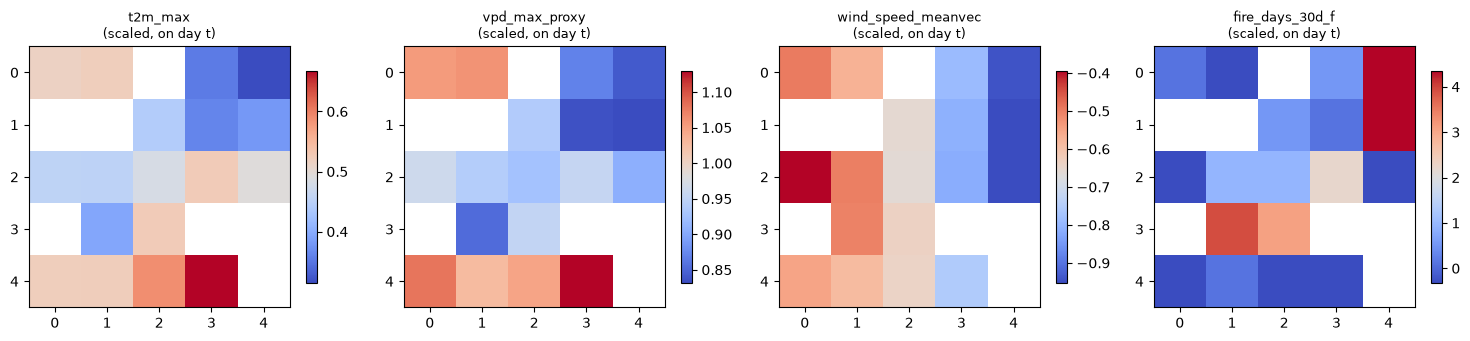

In [5]:
P = patches.Patches(ds, int(r.t), int(r.t), seq=10)                         # loads days t-9 .. t of the cube, scaled
import torch
x, valid = P.batch(torch.tensor([int(r.t)]), torch.tensor([int(r.cell_idx)]))
print("model input x :", tuple(x.shape), "= [samples, days, cells in the 5 x 5 patch, 33 channels + 1 'cell exists' flag]")
print("valid         :", tuple(valid.shape), "= which of the 25 cells really exist")
fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
for a, ch in zip(ax, ["t2m_max", "vpd_max_proxy", "wind_speed_meanvec", "fire_days_30d_f"]):
    m = x[0, -1, :, names.index(ch)].reshape(5, 5).numpy(); m = np.where(valid[0].reshape(5, 5).numpy(), m, np.nan)
    im = a.imshow(m, cmap="coolwarm"); plt.colorbar(im, ax=a, shrink=0.7); a.set_title(f"{ch}\n(scaled, on day t)", fontsize=9); a.grid(False)
plt.tight_layout(); plt.show()

Blank squares are cells that do not exist. The model looks at the picture of the surroundings *and* the 9 earlier days. The centre of each picture is the cell we predict for.

Look at the time dimension for the centre cell:

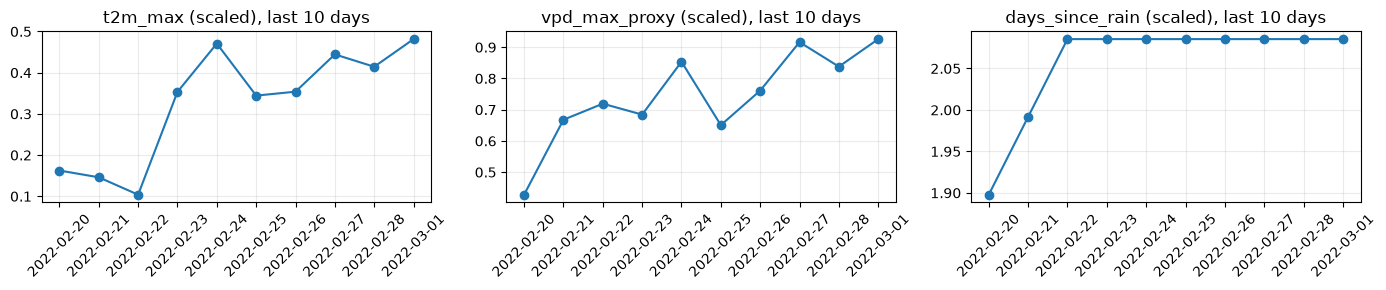

In [6]:
centre = x[0, :, 12, :]                          # [10 days, 34]  (12 = the middle of the 25 cells)
days = [(r.date_t - pd.Timedelta(days=9 - k)).date() for k in range(10)]
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
for a, ch in zip(ax, ["t2m_max", "vpd_max_proxy", "days_since_rain"]):
    a.plot(days, centre[:, names.index(ch)].numpy(), "o-"); a.set_title(ch + " (scaled), last 10 days"); a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 3. How a model uses it (in words)

- **XGBoost** uses only the last day (33 numbers). It has no picture and no memory of the days before, but fire-history channels carry some memory.
- **ConvLSTM** slides small filters over the 5 x 5 picture at each of the 10 days and keeps a memory between days (the LSTM). It sees the neighbourhood and the trend.
- **C1** is ConvLSTM plus attention: it learns which days and which neighbour cells matter most.
- **C2** treats each of the 25 cells as a node with its own 10-day memory, and passes messages between touching nodes (a graph).

All of them end in one number between 0 and 1: the chance of a fire tomorrow in the centre cell.

## 4. What is missing or weak here

- **Cells that do not exist** (non-forest) are filled with zeros, which the model must learn to ignore.
- **Sequence length 10** is a choice, not tested hard. Longer dryness (30 days) is only in the summary channels (`precip_30d`, `days_since_rain`).
- **No wind direction** in the patch, only speed. Fire spreads downwind, so this is a gap.
- **Training mean and sd** come from the training years. A very different year (extreme drought) is scaled by an average that does not fit it.
- Memory: the 10-day patches are cut on demand while training (not stored), because storing them for all 18 million rows would take hundreds of GB.